In [ ]:
import torch
import networkx as nx
import matplotlib.pyplot as plt

# Asumiendo que el notebook está en la carpeta raíz del proyecto (donde está ppo_train_synthetic.py)
from data.data_loader import load_distributions
from model.network_graph_env import NetworkGraphEnv


# Canal + Potencia

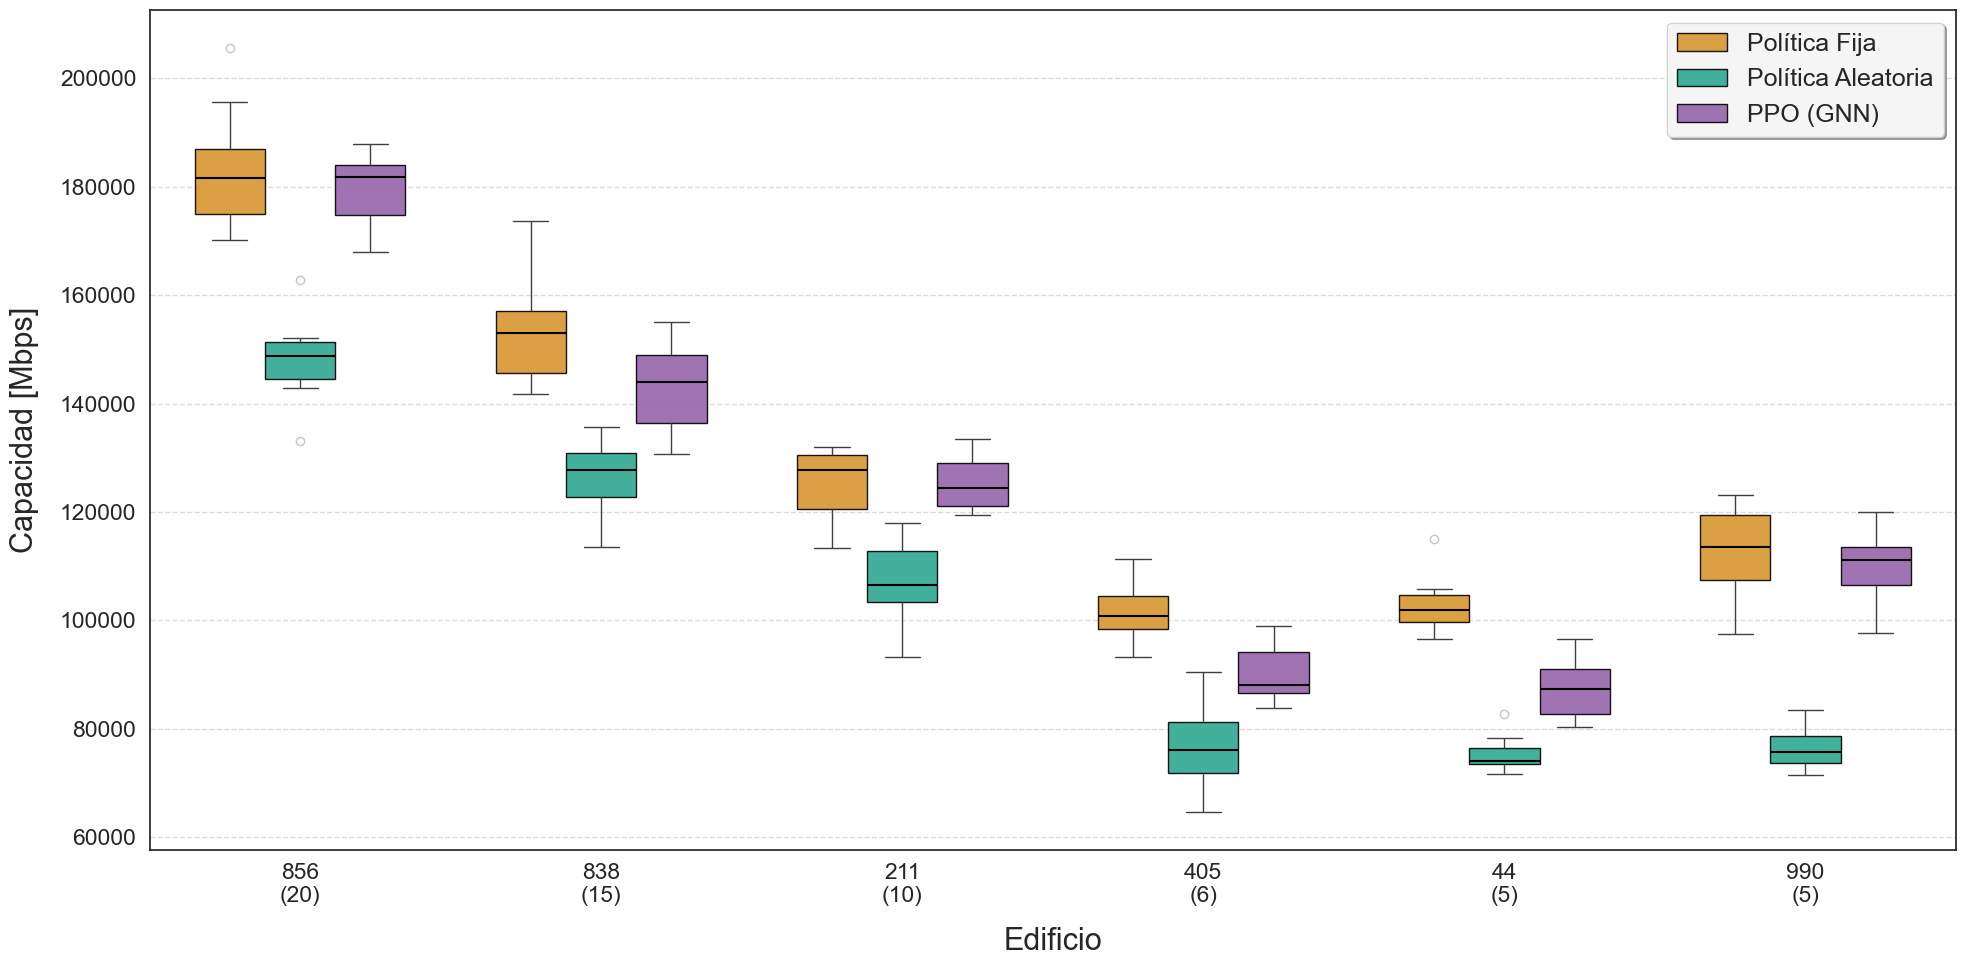

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y filtrar
df = pd.read_csv("outputs/synthetic_models/ase_powers_dp1_600/evals/ajustados/episodes_results.csv")
df = df[df['building_id'] != 79].copy()

# 2. Formatear etiqueta "ID\n(APs)" y sacar el orden automático
df['edificio_label'] = df['building_id'].astype(str) + "\n(" + df['n_aps'].astype(str) + ")"
orden = df.sort_values('n_aps', ascending=False)['edificio_label'].unique()

# 3. Preparar datos para seaborn
df_melted = pd.melt(df, id_vars=['edificio_label'], value_vars=['color_rate', 'random_rate', 'gnn_rate'], 
                    var_name='Política', value_name='Capacidad [Mbps]')

# 4. Cambiá los nombres ACÁ y en la paleta:
df_melted['Política'] = df_melted['Política'].replace({
    'color_rate': 'Política Fija',
    'random_rate': 'Política Aleatoria',
    'gnn_rate': 'PPO (GNN)'
})

paleta = {
    'Política Fija': '#F39C12', 
    'Política Aleatoria': '#1ABC9C', 
    'PPO (GNN)': '#9B59B6'
}

# 5. Graficar
sns.set_theme(style="white", font_scale=1.5)
fig, ax = plt.subplots(figsize=(20, 10))

sns.boxplot(
    data=df_melted, x='edificio_label', y='Capacidad [Mbps]', hue='Política',
    order=orden, palette=paleta, width=0.7, ax=ax,
    boxprops=dict(edgecolor='black', alpha=0.9),
    medianprops=dict(color="black", linewidth=1.5),
    flierprops=dict(marker='o', alpha=0.3)
)

ax.set_xlabel('Edificio', fontsize=22, labelpad=15)
ax.set_ylabel('Capacidad [Mbps]', fontsize=22, labelpad=15)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=18, framealpha=0.9, shadow=True, loc='upper right')

plt.tight_layout()
plt.savefig("outputs/synthetic_models/ase_powers_dp1_600/evals/ajustados/comparativa_cruda.png", dpi=300)
plt.show()


# Comparativa Decision Period

/var/folders/md/0zfzh94s20x4r8fchz8qjg8m0000gn/T/ipykernel_63901/645800048.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


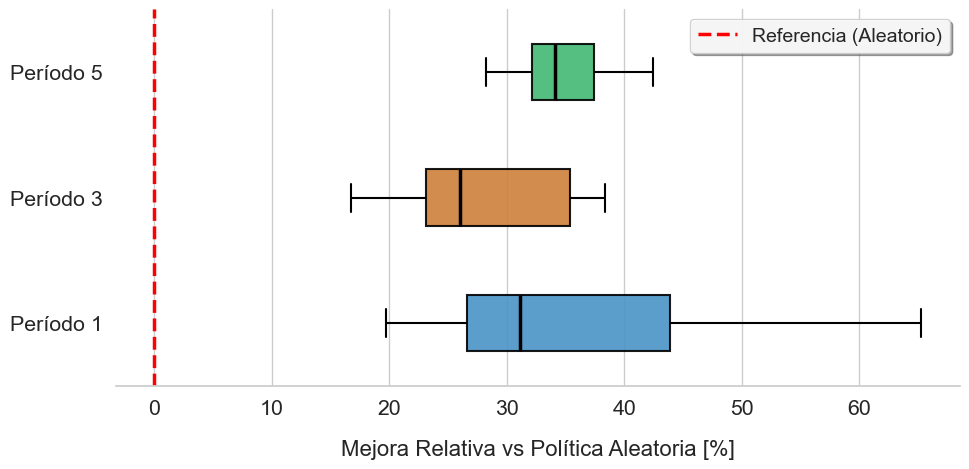

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

# 1. Definir rutas
base_dir = "0_CORE/outputs/synthetic_models/dps_test"
paths = {
    'Período 1': os.path.join(base_dir, "dp1/episodes_results.csv"),
    'Período 3': os.path.join(base_dir, "dp3/episodes_results.csv"),
    'Período 5': os.path.join(base_dir, "dp5/episodes_results.csv")
}

out_dir = Path(base_dir)
out_dir.mkdir(parents=True, exist_ok=True)

# 2. Cargar datos
dfs = []
for label, path in paths.items():
    if os.path.exists(path):
        df_temp = pd.read_csv(path)
        # Calcular mejora de PPO vs Aleatorio
        df_temp['Mejora_Relativa'] = ((df_temp['gnn_rate'] - df_temp['random_rate']) / df_temp['random_rate']) * 100
        df_temp['Período de Decisión'] = label
        dfs.append(df_temp)
    else:
        print(f"Advertencia: No se encontró {path}")

if not dfs:
    print("No se encontraron archivos CSV.")
else:
    df = pd.concat(dfs, ignore_index=True)

    # 3. Tema Global PRO y Paleta
    sns.set_theme(style="whitegrid", font_scale=1.4)

    paleta = {
        'Período 1': '#3498DB',  # Azul
        'Período 3': '#E67E22',  # Naranja
        'Período 5': '#2ECC71'   # Verde
    }

    # 4. Graficar
    fig, ax = plt.subplots(figsize=(10, 5))

    # Definimos el orden explícito (el 5 arriba, el 1 en la base)
    orden_deseado = ['Período 5', 'Período 3', 'Período 1']

    sns.boxplot(
        ax=ax,
        data=df,
        x='Mejora_Relativa',
        y='Período de Decisión',
        order=orden_deseado,
        palette=paleta,
        width=0.45,
        boxprops=dict(edgecolor='black', alpha=0.9, linewidth=1.5),
        medianprops=dict(color="black", linewidth=2.5),
        whiskerprops=dict(linewidth=1.5, color='black'),
        capprops=dict(linewidth=1.5, color='black'),
        flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor='black', markersize=6, alpha=0.8)
    )

    # Baseline: Línea VERTICAL en X=0
    ax.axvline(0, color='red', linestyle='--', linewidth=2.5, label='Referencia (Aleatorio)')

    # Ajuste de ejes y títulos
    ax.set_ylabel('') # Sin texto en Y
    ax.set_xlabel('Mejora Relativa vs Política Aleatoria [%]', fontsize=16, labelpad=15)
    # ax.set_title('Impacto del Período de Decisión (Edificio 990)', pad=20, fontsize=18, fontweight='bold', color='#333333')

    # Leyenda solo para explicar la línea punteada roja
    # Leyenda movida arriba a la derecha
    ax.legend(loc='upper right', fontsize=14, framealpha=0.9, shadow=True)
    
    # Limpiar bordes
    sns.despine(left=True, bottom=False)

    plt.tight_layout()
    plt.savefig("grafica_dp.pdf", format="pdf", bbox_inches="tight")
    plt.show()


# SOLO CANALES

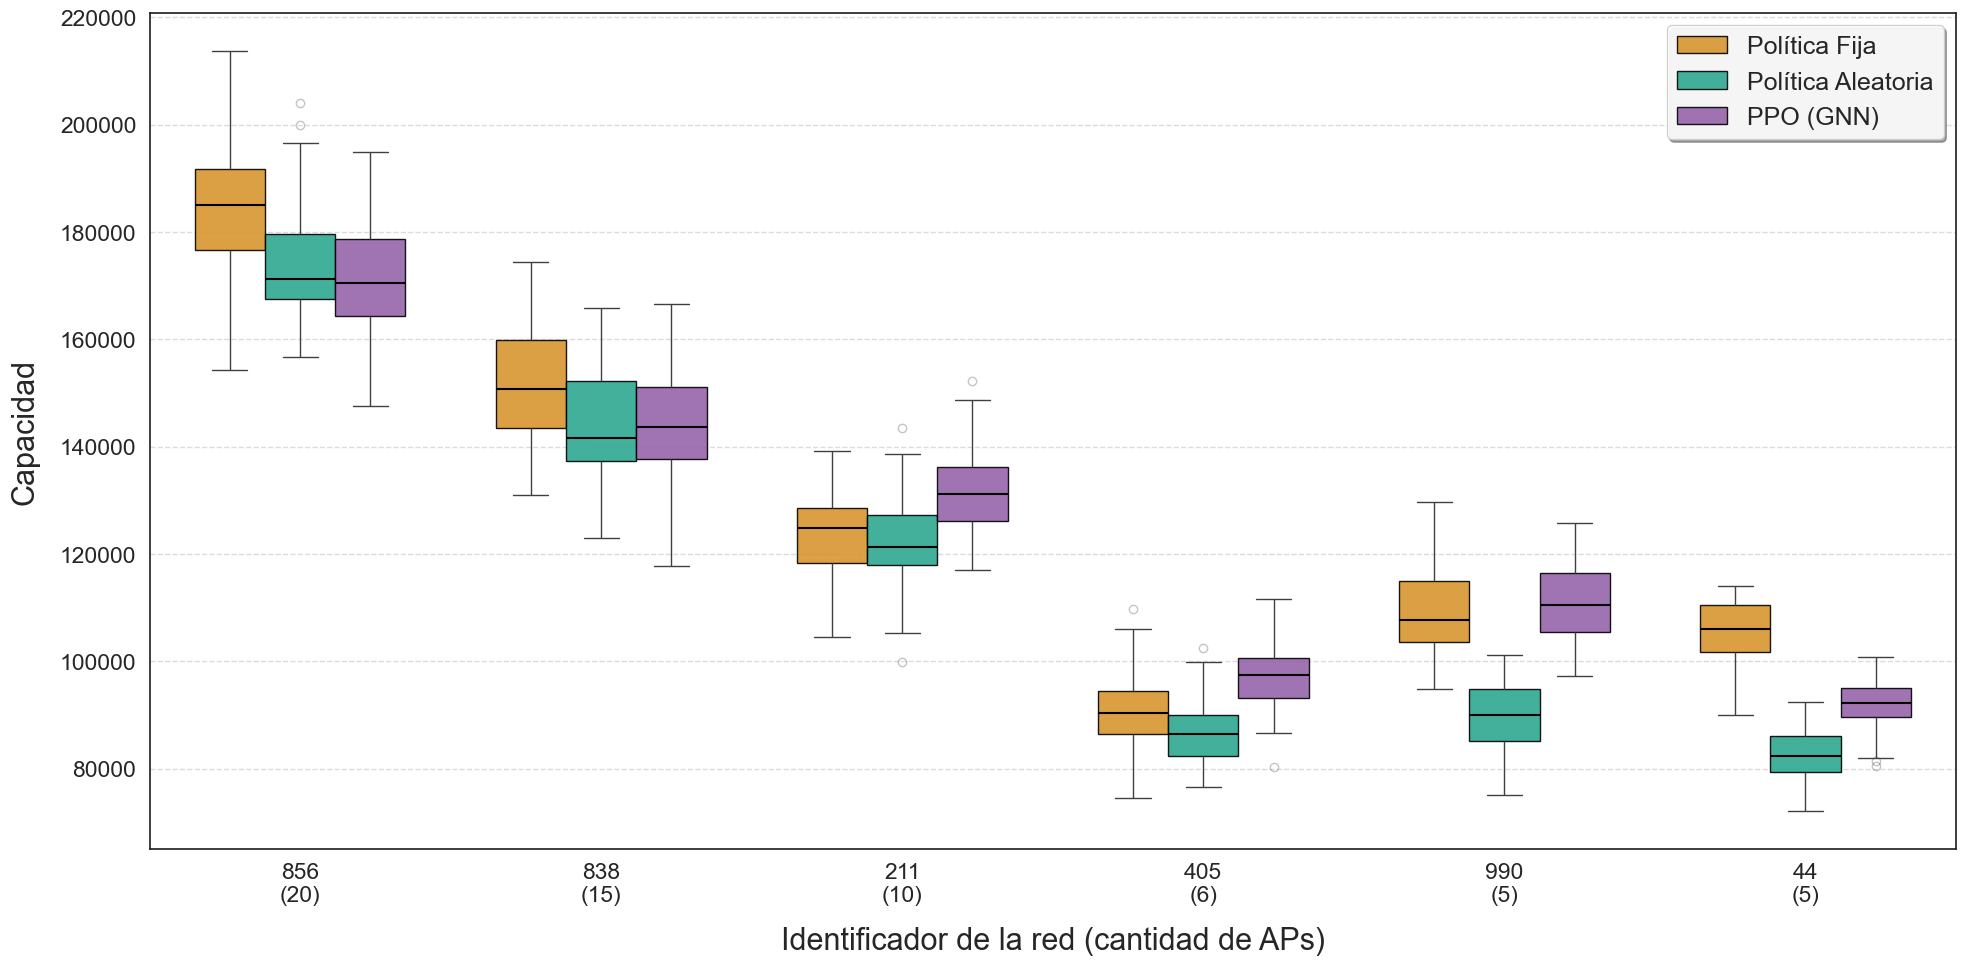

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y filtrar
df = pd.read_csv("0_CORE/outputs/synthetic_models/channels/episodes_results.csv")
df = df[df['building_id'] != 79].copy()

# 2. Formatear etiqueta "ID\n(APs)" y sacar el orden automático
df['edificio_label'] = df['building_id'].astype(str) + "\n(" + df['n_aps'].astype(str) + ")"
orden = df.sort_values('n_aps', ascending=False)['edificio_label'].unique()

# 3. Preparar datos para seaborn
df_melted = pd.melt(df, id_vars=['edificio_label'], value_vars=['color_rate', 'random_rate', 'gnn_rate'], 
                    var_name='Política', value_name='Capacidad [Mbps]')

# 4. Cambiá los nombres ACÁ y en la paleta:
df_melted['Política'] = df_melted['Política'].replace({
    'color_rate': 'Política Fija',
    'random_rate': 'Política Aleatoria',
    'gnn_rate': 'PPO (GNN)'
})

paleta = {
    'Política Fija': '#F39C12', 
    'Política Aleatoria': '#1ABC9C', 
    'PPO (GNN)': '#9B59B6'
}

# 5. Graficar
sns.set_theme(style="white", font_scale=1.5)
fig, ax = plt.subplots(figsize=(20, 10))

sns.boxplot(
    data=df_melted, x='edificio_label', y='Capacidad [Mbps]', hue='Política',
    order=orden, palette=paleta, width=0.7, ax=ax,
    boxprops=dict(edgecolor='black', alpha=0.9),
    medianprops=dict(color="black", linewidth=1.5),
    flierprops=dict(marker='o', alpha=0.3)
)

ax.set_xlabel('Identificador de la red (cantidad de APs)', fontsize=22, labelpad=15)
ax.set_ylabel('Capacidad', fontsize=22, labelpad=15)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=18, framealpha=0.9, shadow=True, loc='upper right')
plt.savefig("grafica_canales.pdf", format="pdf", bbox_inches="tight")

plt.tight_layout()
plt.show()


/var/folders/md/0zfzh94s20x4r8fchz8qjg8m0000gn/T/ipykernel_63901/4005452408.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


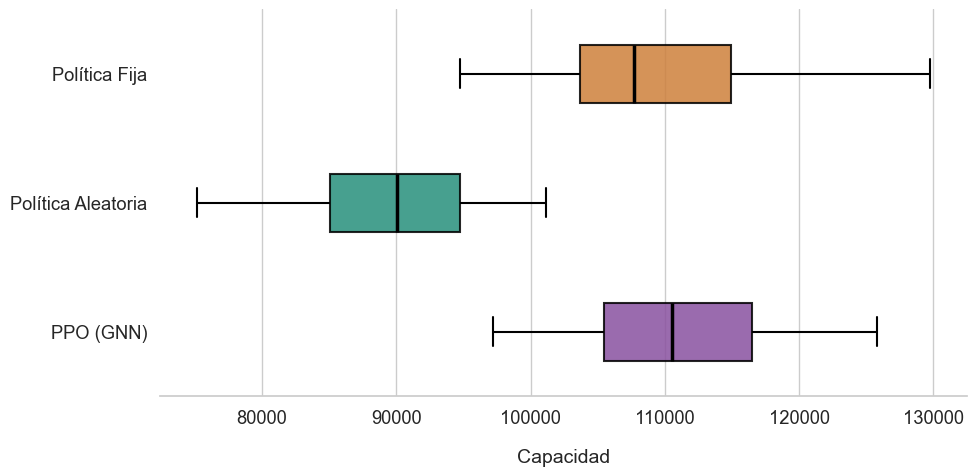

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y filtrar
df = pd.read_csv("0_CORE/outputs/synthetic_models/channels/episodes_results.csv")
df = df[df['building_id'] == 990].copy()

# 2. Formatear
df_melted = pd.melt(df, id_vars=['building_id'], value_vars=['color_rate', 'random_rate', 'gnn_rate'], 
                    var_name='Política', value_name='Capacidad')

df_melted['Política'] = df_melted['Política'].replace({
    'color_rate': 'Política Fija',
    'random_rate': 'Política Aleatoria',
    'gnn_rate': 'PPO (GNN)'
})

paleta = {'Política Fija': '#E67E22', 'Política Aleatoria': '#16A085', 'PPO (GNN)': '#8E44AD'}

# 3. GRAFICAR (Boxplot Horizontal)
sns.set_theme(style="whitegrid", font_scale=1.2)
fig, ax = plt.subplots(figsize=(10, 5)) # Mucho más proporcionado (ancho vs alto)

# Para hacerlo horizontal: y='Política', x='Capacidad [Mbps]'
sns.boxplot(
    data=df_melted, x='Capacidad', y='Política', 
    palette=paleta, 
    width=0.45, # Cajas más estilizadas, no tan gordas
    boxprops=dict(edgecolor='black', alpha=0.85, linewidth=1.5),
    medianprops=dict(color='black', linewidth=2.5), # Mediana muy clara
    whiskerprops=dict(linewidth=1.5, color='black'),
    capprops=dict(linewidth=1.5, color='black'),
    flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor='black', alpha=0.8),
    ax=ax
)

# Ajustes estéticos finales
ax.set_ylabel('') # No hace falta título en Y, las etiquetas ya lo explican
ax.set_xlabel('Capacidad', fontsize=14, labelpad=15)
# ax.set_title('Rendimiento en Edificio 990', pad=20, fontsize=16, fontweight='bold', color='#333333')

# Quitamos el borde izquierdo para que parezca que las etiquetas flotan elegantemente
sns.despine(left=True, bottom=False)

plt.tight_layout()
plt.savefig("grafica_canales_990_boxplot_horizontal.pdf", format="pdf")
plt.show()


# Pruebas Sticky

/opt/miniconda3/envs/torch-mps/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


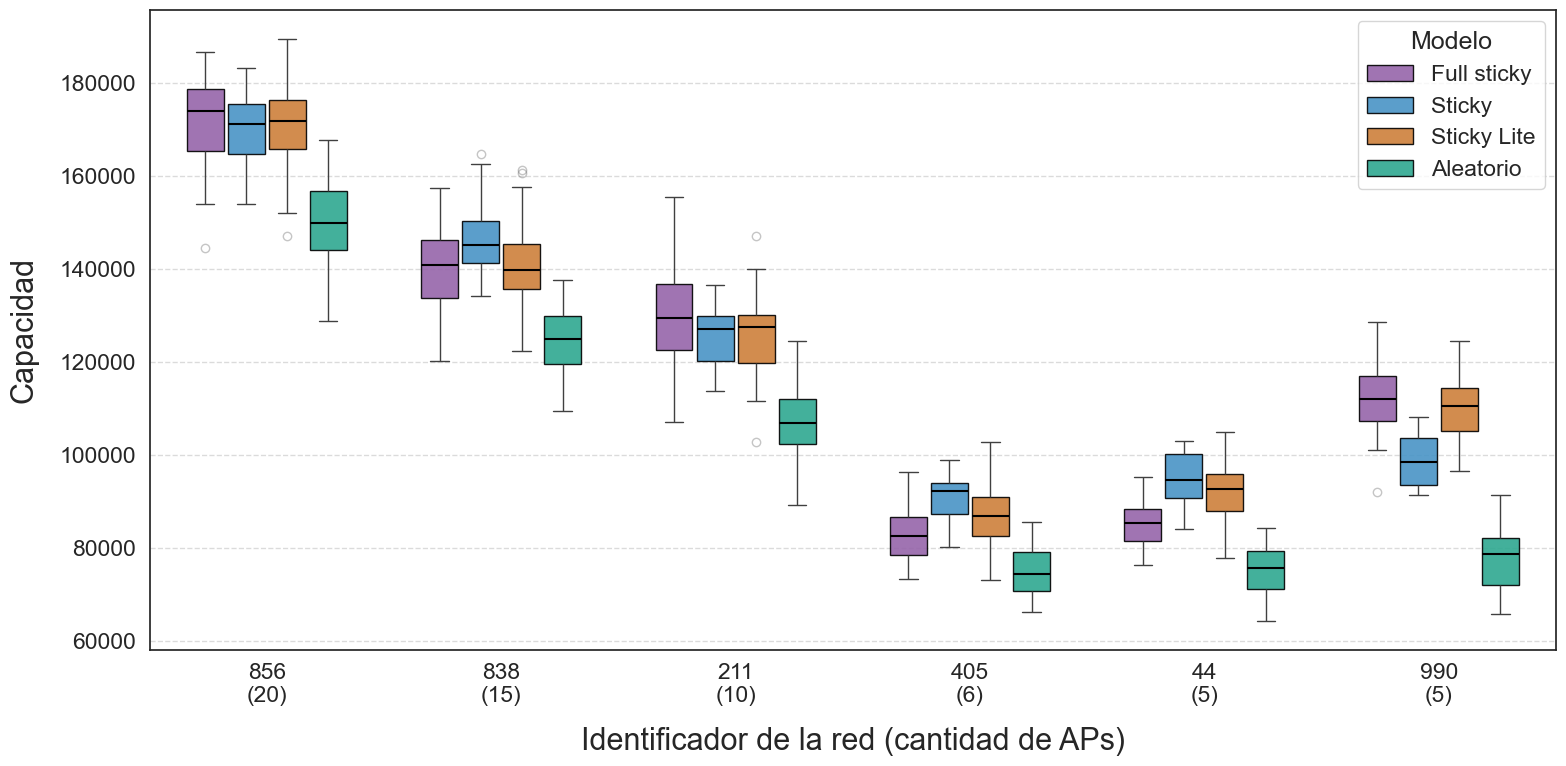

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Rutas exactas de los archivos
paths = {
    'Full sticky': '/Users/nahuelpineyro/WL-3/0_CORE/outputs/synthetic_models/full/episodes_results.csv',
    'Sticky': '/Users/nahuelpineyro/WL-2/0_CORE/outputs/synthetic_models/STD/episodes_results.csv',
    'Sticky Lite': '/Users/nahuelpineyro/WL-4/0_CORE/outputs/synthetic_models/LITE/episodes_results.csv'
}

# 2. Cargar y concatenar datos
dfs = []
for label, path in paths.items():
    if os.path.exists(path):
        df_temp = pd.read_csv(path)
        df_temp['Modelo'] = label  # Agregamos la columna que identifica la variante
        dfs.append(df_temp)
    else:
        print(f"Advertencia: No se encontró el archivo en {path}")

if not dfs:
    print("No se encontró ningún CSV para graficar.")
else:
    df = pd.concat(dfs, ignore_index=True)

    # 3. Filtrar el edificio 79
    df = df[df['building_id'] != 79].copy()

    # 4. Formatear etiqueta "ID\n(APs)" y sacar el orden automático
    df['edificio_label'] = df['building_id'].astype(str) + "\n(" + df['n_aps'].astype(str) + ")"
    # Ordenar de mayor a menor cantidad de APs
    orden = df.sort_values('n_aps', ascending=False)['edificio_label'].unique()

    # 5. Extraer únicamente el rendimiento de PPO (gnn_rate)
    df_gnn = df[['edificio_label', 'gnn_rate', 'Modelo']].copy()
    df_gnn.rename(columns={'gnn_rate': 'Capacidad'}, inplace=True)

    # ---> NUEVO: Extraer el random_rate del modelo 'Full' <---
    df_full = df[df['Modelo'] == 'Full sticky'].copy()
    if not df_full.empty:
        df_random = df_full[['edificio_label', 'random_rate']].copy()
        df_random['Modelo'] = 'Aleatorio' # Lo bautizamos como Aleatorio
        df_random.rename(columns={'random_rate': 'Capacidad'}, inplace=True)
        
        # Unimos este nuevo "modelo" al dataframe principal
        df_gnn = pd.concat([df_gnn, df_random], ignore_index=True)

    # Definir paleta de colores para los 4 modelos (agregué un gris para Aleatorio)
    paleta = {
        'Full sticky': '#9B59B6',    # Violeta
        'Sticky': '#3498DB',     # Azul
        'Sticky Lite': '#E67E22',    # Naranja
        'Aleatorio': '#1ABC9C' # Verde (Baseline)
    }

    # 6. Graficar
    sns.set_theme(style="white", font_scale=1.5)
    fig, ax = plt.subplots(figsize=(16, 8))  # Formato cuadrado/ancho

    sns.boxplot(
        data=df_gnn, x='edificio_label', y='Capacidad', hue='Modelo',
        order=orden, palette=paleta, 
        width=0.7, # Aumenté un poquito el ancho para que quepan bien las 4 cajas
        gap=0.1,   
        ax=ax,
        boxprops=dict(edgecolor='black', alpha=0.9),
        medianprops=dict(color="black", linewidth=1.5),
        flierprops=dict(marker='o', alpha=0.3)
    )

    # Detalles estéticos
    ax.set_xlabel('Identificador de la red (cantidad de APs)', fontsize=22, labelpad=15)
    ax.set_ylabel('Capacidad', fontsize=22, labelpad=15)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.set_axisbelow(True)
    
    # Leyenda (descomentada para que puedas ver cuál es cuál)
    # ax.legend(title='Variante', title_fontsize=20, fontsize=18, 
    #           framealpha=0.9, shadow=True, loc='upper right')

    plt.tight_layout()
    plt.savefig("grafica_sticky_new.pdf", format="pdf", bbox_inches="tight", dpi=300)

    # Mostrar la gráfica
    plt.show()


In [ ]:
# 1. Configuración Vectorial para Jupyter
%config InlineBackend.figure_format = 'svg'

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

# =======================================================
# CONFIGURACIÓN ESTÉTICA ESTILO TESIS / PAPER
# =======================================================
sns.set_theme(
    style="ticks", 
    context="paper",
    rc={
        "font.family": "serif", 
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.grid": True,
        "grid.color": "#e0e0e0",
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# 2. Cargar y procesar datos
df = pd.read_csv('./data/dataset_211_step2.csv')
df_validos = df.dropna(subset=['rssi'])
mac_ap = df_validos['mac_ap'].value_counts().index[0]
df_ap = df_validos[df_validos['mac_ap'] == mac_ap]

# Obtener TODOS los clientes que tengan un mínimo de datos para que la media sea válida
conteo = df_ap['mac_cliente'].value_counts()
clientes_generales = conteo[conteo >= 5].index 
# Ya no buscamos a los más estables, ¡usamos a toda la población válida!

print(f"📊 Analizando el ruido de la población general: {len(clientes_generales)} dispositivos distintos.")

# Aislar el ruido centrado en 0 para TODA LA POBLACIÓN
ruido_total = []
for mac in clientes_generales:
    datos = df_ap[df_ap['mac_cliente'] == mac]['rssi']
    # Restar la media aísla el comportamiento estocástico general (el ruido)
    ruido_total.extend(datos - datos.mean())
    
ruido_total = np.array(ruido_total)

# =======================================================
# GRAFICACIÓN CIENTÍFICA (Población General)
# =======================================================
plt.figure(figsize=(16, 5)) 

# Histograma de los datos empíricos de TODA la población
sns.histplot(
    ruido_total, 
    bins=30, # Usamos un par más de bins porque hay muchos más datos
    stat='density', 
    alpha=0.7, 
    color='#F39C12', 
    edgecolor='white', 
    # label=f'Ruido Empírico Global (N={len(ruido_total)} muestras)'
)

# Cálculo de la curva teórica general
mu, std = np.mean(ruido_total), np.std(ruido_total)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mu, std)

# Campana de Gauss teórica
plt.plot(
    x, p, 'k', 
    linewidth=2.5, 
    color='#1ABC9C', 
    label=f'Ajuste Teórico: $\mathcal{{N}}(\mu={mu:.2f}, \sigma={std:.2f}^2)$'
)

# paleta = {
#     'Política Fija': '#F39C12', 
#     'Política Aleatoria': '#1ABC9C', 
#     'PPO (GNN)': '#9B59B6'
# }

# plt.title('Análisis Estocástico de Población General (Todos los Dispositivos)\nVerificación del Supuesto de Ruido Gaussiano', 
        #   fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Desviación RSSI Normalizada ($\Delta$ dBm)', fontsize=20, labelpad=10)
plt.ylabel('Densidad de Probabilidad', fontsize=20, labelpad=10)

plt.legend(frameon=False, fontsize=20, loc='upper right')
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.tight_layout()

# Guardar gráficos para la tesis
plt.savefig("verificacion_poblacion_general.svg", format="svg", bbox_inches='tight')
plt.savefig("verificacion_poblacion_general.pdf", format="pdf", bbox_inches='tight')

plt.show()
